# 길잡이들 안전점수 계산 — 단계별

`scripts/score.py`의 함수를 그대로 불러서 단계마다 중간 결과를 찍는 발표 캡처용 노트북입니다. 계산 방식은 `score.py`와 같고,
마지막 저장(`public/data/`)은 하지 않습니다. 실행에는 인터넷이 필요합니다 (OSM 도로망·구역, 저장소 `cache/`에 있으면 그걸 씀).

In [1]:
# 0) 준비: 저장소 루트로 이동하고 scripts/score.py를 불러옴 (OSM 캐시 cache/도 루트 기준)
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "scripts" / "score.py").exists())
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "scripts"))

import numpy as np, pandas as pd, geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import score
from score import INDICATORS, CLEAN, CRS_M, MIN_LEN

pd.set_option("display.width", 200)
plt.rcParams["font.family"] = "Malgun Gothic"    # 한글 폰트
plt.rcParams["axes.unicode_minus"] = False
print("저장소:", ROOT)

저장소: C:\Users\HSystem\Downloads\giljabi


In [2]:
# 1) 데이터 불러오기: data/clean/의 시설 파일별 행 수·시설 수(count 합)·기준일
LABELS = {"light": "보안등", "cctv": "CCTV", "shop": "상가", "bell": "비상벨", "police": "지구대", "store": "편의점"}
rows = []
for key, label in LABELS.items():
    df = pd.read_csv(CLEAN / f"{key}_namgu.csv", encoding="utf-8-sig", dtype={"base_date": str})
    rows.append({"데이터": label, "파일": f"{key}_namgu.csv", "행 수": len(df), "시설 수(count 합)": int(df["count"].sum()),
                 "기준일": df["base_date"].dropna().max(), "점수 지표": "○" if key in INDICATORS else "지도 표시만"})
display(pd.DataFrame(rows))

import rasterio
with rasterio.open(CLEAN / INDICATORS["slope"]["file"]) as src:
    print(f"경사도 DEM: {INDICATORS['slope']['file']} / {src.width}×{src.height}칸, 해상도 {abs(src.res[0]):.0f}m, 좌표계 {src.crs}")

,데이터,파일,행 수,시설 수(count 합),기준일,점수 지표
0,보안등,light_namgu.csv,4831,5232,2026-10-28,○
1,CCTV,cctv_namgu.csv,861,2074,2026-05-07,○
2,상가,shop_namgu.csv,4066,9326,2026-09,○
3,비상벨,bell_namgu.csv,80,84,2026-01-01,지도 표시만
4,지구대,police_namgu.csv,7,7,2025-12-31,지도 표시만
5,편의점,store_namgu.csv,153,175,2026-09,지도 표시만


경사도 DEM: dem_namgu.tif / 73×67칸, 해상도 90m, 좌표계 EPSG:5179


In [3]:
# 2) 보행 도로망 받기(OSM, 4곳 중심 반경 1,200m) + 밤에 걸을 수 없는 길 제외
Gp, nodes, edges, polygon = score.load_network()
before = len(edges)
Gp, nodes, edges = score.drop_unwalkable(Gp, polygon)
display(pd.DataFrame({"구간 수": [before, len(edges), before - len(edges)]}, index=["제외 전", "제외 후", "뺀 구간"]))

경성대학교: (35.1406608, 129.0980524)
부경대학교 대연캠퍼스: (35.1342725, 129.1052466)
경성대·부경대역: (35.137539, 129.100524)
대연역: (35.135132, 129.092166)


도로 구간 수: 7710 / 교차점 수: 2965


[보행망 정리] 운전면허시험장 코스 100 / 출입 금지 0 / 묘역 안 206 (주 묘역) / 이용 시간 있는 구역 안 322 (재한국 국제연합 기념공원) → 합계 422구간 뺌


,구간 수
제외 전,7710
제외 후,7288
뺀 구간,422


In [4]:
# 3) 구간별 반경 안 시설 수와 밀도 (밀도 = 반경 안 시설 수 ÷ 구간 길이(최소 20m) × 100)
raw_ind = {}
for key, cfg in INDICATORS.items():
    if key == "slope":
        continue
    raw_ind[key] = score.facility_density(edges, key, cfg)

length = edges["length"].clip(lower=MIN_LEN)
table = pd.DataFrame({"도로 이름": edges["name"].apply(score.first_tag), "도로 종류": edges["highway"].apply(score.first_tag),
                      "길이(m)": edges["length"].round(1)})
for key in raw_ind:
    table[f"{key} 수"] = (raw_ind[key] * length / 100).round().astype(int)
    table[f"{key} 밀도"] = raw_ind[key].round(2)
print("반경:", {k: f"{c['radius']}m" for k, c in INDICATORS.items() if c["radius"]})
print("시설이 하나라도 있는 구간 5개 미리보기")
display(table[(table[[f"{k} 수" for k in raw_ind]] > 0).any(axis=1)].head(5).reset_index(drop=True))

[light] 시설 4831개 사용, 시설 있는 구간 비율 30%


[cctv] 시설 861개 사용, 시설 있는 구간 비율 36%


[shop] 시설 4066개 사용, 시설 있는 구간 비율 46%
반경: {'light': '25m', 'cctv': '50m', 'shop': '50m'}
시설이 하나라도 있는 구간 5개 미리보기


,도로 이름,도로 종류,길이(m),light 수,light 밀도,cctv 수,cctv 밀도,shop 수,shop 밀도
0,유엔로157번가길,residential,124.6,4,3.21,13,10.44,12,9.63
1,유엔로169번길,residential,46.0,2,4.35,5,10.86,5,10.86
2,유엔로157번가길,residential,146.3,7,4.78,9,6.15,7,4.78
3,유엔로169번길,residential,40.1,2,4.99,5,12.47,6,14.96
4,유엔로157번길,residential,45.3,3,6.63,11,24.31,16,35.35


In [5]:
# 4) 인도·횡단보도는 바로 옆 차도의 시설 밀도를 같이 씀 (max(자기, 옆 차도)) → 시설 0 비율 비교
hw = edges["highway"].apply(score.first_tag)
fw = edges["footway"].apply(score.first_tag)
is_share = (hw == "footway") & fw.isin(score.SHARE_FOOTWAY)
before_ind = {k: v.copy() for k, v in raw_ind.items()}

print("(아래 [light]·[cctv]·[shop] 줄은 짝지을 차도망 기준 밀도 계산)")
score.share_with_road(edges, raw_ind, polygon)   # raw_ind를 그 자리에서 바꿈

def zero_ratio(ind, mask):
    r = {INDICATORS_LABEL[k]: f"{(v[mask] == 0).mean():.1%}" for k, v in ind.items()}
    r["세 시설 모두 0"] = f"{(pd.concat(ind, axis=1)[mask] == 0).all(axis=1).mean():.1%}"
    return r
INDICATORS_LABEL = {"light": "보안등 0", "cctv": "CCTV 0", "shop": "상가 0"}
all_rows = pd.Series(True, index=edges.index)
display(pd.DataFrame({
    f"인도·횡단보도 {is_share.sum()}구간 — 적용 전": zero_ratio(before_ind, is_share),
    "적용 후": zero_ratio(raw_ind, is_share),
    f"전체 {len(edges)}구간 — 적용 전": zero_ratio(before_ind, all_rows),
    "적용 후 ": zero_ratio(raw_ind, all_rows),
}).T)
print("큰길·큰길 옆 인도(가로등 미반영, streetlight_missing):", int(edges["streetlight_missing"].sum()), "구간")

(아래 [light]·[cctv]·[shop] 줄은 짝지을 차도망 기준 밀도 계산)


[light] 시설 4831개 사용, 시설 있는 구간 비율 67%
[cctv] 시설 861개 사용, 시설 있는 구간 비율 71%
[shop] 시설 4066개 사용, 시설 있는 구간 비율 82%
[인도·횡단보도] 1386구간 중 668구간이 30m 안 차도와 짝지어짐


,보안등 0,CCTV 0,상가 0,세 시설 모두 0
인도·횡단보도 1386구간 — 적용 전,96.2%,88.9%,79.4%,73.9%
적용 후,91.1%,74.0%,70.1%,59.6%
전체 7288구간 — 적용 전,70.5%,63.5%,53.6%,47.4%
적용 후,69.5%,60.7%,51.9%,44.6%


큰길·큰길 옆 인도(가로등 미반영, streetlight_missing): 1262 구간


In [6]:
# 5) 경사도 → 지표별 0~1 정규화(상위 5% 자르고 min-max, 경사는 평평할수록 1) → 가중합 = 안전점수
s = score.slope_grade(nodes, edges)
raw_ind["slope"] = s

paper_w = {k: c["w"] for k, c in INDICATORS.items()}
edges["safety"], used_w = score.safety_score(raw_ind, paper_w)
for k in raw_ind:
    edges[f"{k}_n"] = score.normalize(raw_ind[k], INDICATORS[k]["higher_is_safer"])
edges["risk"] = 1 - edges["safety"]
edges["cost"] = edges["length"] * (1 + edges["risk"])
edges["grade"] = score.to_grade(edges["safety"])

NAMES = {"light": "보안등 밀도", "cctv": "CCTV 밀도", "shop": "상가 밀도", "slope": "경사도"}
display(pd.DataFrame([{"지표": NAMES[k], "논문 가중치": c["w"], "적용 가중치(합 1)": used_w[k],
                       "반경": f"{c['radius']}m" if c["radius"] else "-", "방향": "많을수록 안전" if c["higher_is_safer"] else "평평할수록 안전",
                       "정규화 평균": round(edges[f"{k}_n"].mean(), 3)} for k, c in INDICATORS.items()]))
print("안전점수 = " + " + ".join(f"{used_w[k]}·{k}_n" for k in INDICATORS))

summary = pd.DataFrame({"안전도(0~1)": edges["safety"].describe(), "점수(0~100)": (edges["safety"] * 100).describe()}).round(3)
display(summary.T)
print("등급별 구간 수 (1 안전 ~ 5 위험, 분위수):", edges["grade"].value_counts().sort_index().to_dict())

# 확인: 앱이 쓰는 public/data/edges_scored.geojson과 같은 값인지 (저장할 때 소수 4자리로 반올림)
saved = gpd.read_file(ROOT / "public" / "data" / "edges_scored.geojson")
diff = np.abs(np.sort(edges["safety"].round(4).values) - np.sort(saved["safety"].values)).max() if len(saved) == len(edges) else None
print(f"저장된 파일: {len(saved)}구간 / 이 노트북: {len(edges)}구간 / 안전도 최대 차이: {diff}")

경사도(%) 요약:
count    7288.0
mean        3.8
std         9.7
min         0.0
25%         0.0
50%         0.0
75%         3.3
max       142.8
dtype: float64


,지표,논문 가중치,적용 가중치(합 1),반경,방향,정규화 평균
0,보안등 밀도,0.207,0.414,25m,많을수록 안전,0.168
1,CCTV 밀도,0.178,0.356,50m,많을수록 안전,0.158
2,상가 밀도,0.084,0.168,50m,많을수록 안전,0.163
3,경사도,0.031,0.062,-,평평할수록 안전,0.847


안전점수 = 0.414·light_n + 0.356·cctv_n + 0.168·shop_n + 0.062·slope_n


,count,mean,std,min,25%,50%,75%,max
안전도(0~1),7288.0,0.206,0.225,0.0,0.062,0.068,0.325,1.0
점수(0~100),7288.0,20.590,22.497,0.0,6.200,6.776,32.533,100.0


등급별 구간 수 (1 안전 ~ 5 위험, 분위수): {1: 1458, 2: 1457, 3: 1458, 4: 1457, 5: 1458}


저장된 파일: 7288구간 / 이 노트북: 7288구간 / 안전도 최대 차이: 0.0


In [7]:
# 6) 공공데이터가 없는 구역 표시 (점수는 그대로, 아파트·캠퍼스·학교·남구 밖은 앱에서 회색)
score.tag_areas(edges, polygon)

AREA_KO = {"apartment": "아파트 단지", "campus": "캠퍼스", "school": "학교", "park": "공원", "outside_namgu": "남구 밖", None: "(구역 아님)"}
g = edges.groupby(edges["area_type"].fillna("(none)"))
area = pd.DataFrame({"구간 수": g.size(), "길이(km)": (g["length"].sum() / 1000).round(1), "평균 점수": (g["safety"].mean() * 100).round(1)})
area.index = [AREA_KO.get(None if i == "(none)" else i, i) for i in area.index]
area["구간 비율"] = (area["구간 수"] / len(edges)).map("{:.1%}".format)
area["길이 비율"] = (area["길이(km)"] / area["길이(km)"].sum()).map("{:.1%}".format)
area["앱 표시"] = ["회색(공공데이터 미포함)" if k in score.NO_BLINDSPOT_AREAS else "안전도 색" for k in g.size().index]
display(area.sort_values("구간 수", ascending=False))

[구역] park: 폴리곤 38개
[구역] apartment: 폴리곤 33개
[구역] school: 폴리곤 24개
[구역] campus: 폴리곤 6개
[구역] outside_namgu: 경계 'Nam-gu, Busan, South Korea' (OSM relation 4068408)
               size  구간 비율  길이 비율
area_type                        
(없음)           3594  49.3%  58.8%
apartment      1950  26.8%  16.3%
campus          628   8.6%   8.0%
outside_namgu   846  11.6%  12.8%
park            168   2.3%   2.9%
school          102   1.4%   1.1%


,구간 수,길이(km),평균 점수,구간 비율,길이 비율,앱 표시
(구역 아님),3594,216.5,33.7,49.3%,58.8%,안전도 색
아파트 단지,1950,60.2,7.1,26.8%,16.3%,회색(공공데이터 미포함)
남구 밖,846,47.0,5.2,11.6%,12.8%,회색(공공데이터 미포함)
캠퍼스,628,29.6,8.0,8.6%,8.0%,회색(공공데이터 미포함)
공원,168,10.8,26.5,2.3%,2.9%,안전도 색
학교,102,4.2,11.4,1.4%,1.1%,회색(공공데이터 미포함)


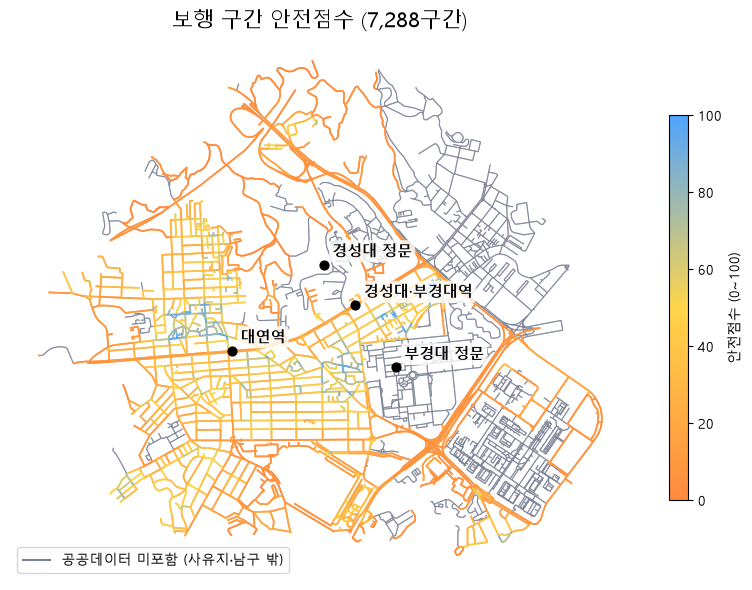

In [8]:
# 7) 결과 지도: 구간을 안전도로 색칠 (주황 위험 → 노랑 → 파랑 안전, 회색 = 공공데이터 미포함) — 앱과 같은 색
cmap = LinearSegmentedColormap.from_list("giljabi", [(0, "#FF8A3D"), (0.5, "#FFD54A"), (1, "#4FA3FF")])
NO_DATA = {"apartment", "campus", "school", "outside_namgu"}
no_data = edges["area_type"].isin(NO_DATA)
PLACES = {"경성대 정문": (35.139813, 129.098437), "부경대 정문": (35.134062, 129.103187),
          "대연역": (35.135132, 129.092166), "경성대·부경대역": (35.137539, 129.100524)}

fig, ax = plt.subplots(figsize=(10, 10))
edges[no_data].plot(ax=ax, color="#7A8194", linewidth=0.8, alpha=0.7)
edges[~no_data].plot(ax=ax, column="safety", cmap=cmap, vmin=0, vmax=1, linewidth=1.2)
pts = gpd.GeoSeries(gpd.points_from_xy([v[1] for v in PLACES.values()], [v[0] for v in PLACES.values()]), crs="EPSG:4326").to_crs(CRS_M)
ax.scatter(pts.x, pts.y, s=40, c="black", zorder=5)
for name, p in zip(PLACES, pts):
    ax.annotate(name, (p.x, p.y), xytext=(6, 6), textcoords="offset points", fontsize=11, weight="bold",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.8))
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 100))
fig.colorbar(sm, ax=ax, shrink=0.5, label="안전점수 (0~100)")
ax.plot([], [], color="#7A8194", label="공공데이터 미포함 (사유지·남구 밖)")
ax.legend(loc="lower left")
ax.set_title(f"보행 구간 안전점수 ({len(edges):,}구간)", fontsize=15)
ax.set_axis_off()
plt.show()

,k,거리(m),평균 점수(화면),고를 때 점수,공공데이터 미포함(m),우회
경로,,,,,,
최단,"[0, 1]",1096.9,19.4,22.4,319.4,+0.0%
안심,[8],1231.0,35.2,33.8,319.4,+12.2%


후보 3개 (k별): [([0, 1], 1097, 22.4), ([2, 4], 1116, 25.3), ([8], 1231, 33.8)]


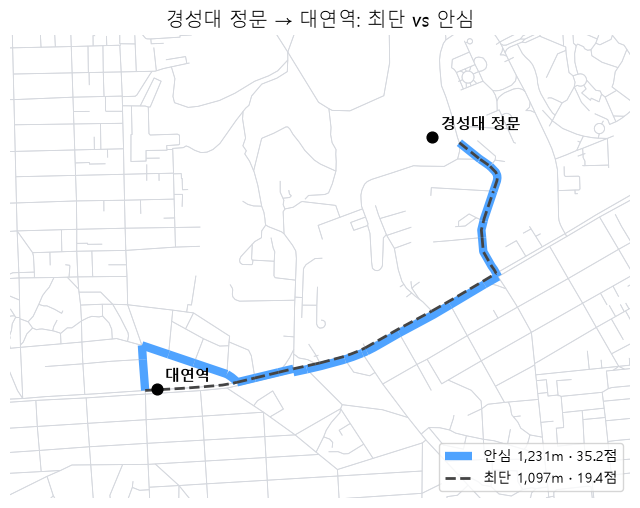

In [9]:
# 8) 최단 경로 vs 안심 경로 예시: 경성대 정문 → 대연역 (앱 src/lib/route.js와 같은 방식을 파이썬으로 옮김)
#    후보: 비용 = 길이 × (1 + k × 위험도), k = 0(최단)·1·2·4·8 / 최단 대비 +25% 안에서 평균 안전점수가 가장 높은 후보
#    공공데이터 미포함 구간은 고를 때만 공공데이터 구간 안전도 중앙값으로 바꿔 씀, 화면 점수에서는 뺌
import heapq
K_VALUES, MAX_DETOUR = [0, 1, 2, 4, 8], 0.25
E = edges.reset_index().to_crs("EPSG:4326")
E["length"] = E["length"].round(2); E["safety"] = E["safety"].round(4)   # 앱이 읽는 파일과 같은 자릿수
nd = E["area_type"].isin(NO_DATA).to_numpy()
pick = np.where(nd, np.median(E.loc[~nd, "safety"]), E["safety"])

adj, node_xy = {}, {}
for i, (u, v, geom) in enumerate(zip(E["u"], E["v"], E.geometry)):
    c = geom.coords
    node_xy.setdefault(u, (c[0][1], c[0][0])); node_xy.setdefault(v, (c[-1][1], c[-1][0]))
    adj.setdefault(u, []).append((v, i))

def dist_m(a, b):   # 위경도 두 점 거리(m), route.js distM과 같은 근사
    k = np.pi / 180
    x = (b[1] - a[1]) * k * np.cos((a[0] + b[0]) / 2 * k); y = (b[0] - a[0]) * k
    return np.hypot(x, y) * 6371000

def nearest(latlng):
    return min(node_xy, key=lambda n: dist_m(latlng, node_xy[n]))

def dijkstra(s, t, w):
    dist, prev, heap = {s: 0}, {}, [(0, s)]
    while heap:
        d, n = heapq.heappop(heap)
        if n == t: break
        if d > dist[n]: continue
        for m, i in adj.get(n, []):
            nd_ = d + w[i]
            if nd_ < dist.get(m, np.inf):
                dist[m] = nd_; prev[m] = (n, i); heapq.heappush(heap, (nd_, m))
    path, n = [], t
    while n != s:
        n, i = prev[n]; path.append(i)
    return path[::-1]

L, S = E["length"].to_numpy(), E["safety"].to_numpy()
def summarize(path):
    p = np.array(path); known = p[~nd[p]]
    return {"거리(m)": L[p].sum(), "평균 점수(화면)": (S[known] * L[known]).sum() / L[known].sum() * 100,
            "고를 때 점수": (pick[p] * L[p]).sum() / L[p].sum() * 100, "공공데이터 미포함(m)": L[p[nd[p]]].sum(), "path": path}

s, t = nearest(PLACES["경성대 정문"]), nearest(PLACES["대연역"])
cands = {}
for k in K_VALUES:
    path = dijkstra(s, t, L * (1 + k * (1 - pick)))
    cands.setdefault(tuple(path), {"k": [], **summarize(path)})["k"].append(k)
cands = list(cands.values())
short = min(cands, key=lambda c: c["거리(m)"])
safe = max([c for c in cands if c["거리(m)"] <= short["거리(m)"] * (1 + MAX_DETOUR)], key=lambda c: (c["고를 때 점수"], -c["거리(m)"]))

res = pd.DataFrame([{"경로": "최단", **short}, {"경로": "안심", **safe}]).drop(columns="path").set_index("경로")
res["우회"] = (res["거리(m)"] / short["거리(m)"] - 1).map("{:+.1%}".format)
display(res.round(1))
print(f"후보 {len(cands)}개 (k별):", [(c["k"], round(c["거리(m)"]), round(float(c["고를 때 점수"]), 1)) for c in cands])

fig, ax = plt.subplots(figsize=(8, 7))
E.plot(ax=ax, color="#D5D8DE", linewidth=0.6)
E.iloc[safe["path"]].plot(ax=ax, color="#4FA3FF", linewidth=6, label=f"안심 {safe['거리(m)']:,.0f}m · {safe['평균 점수(화면)']:.1f}점")
E.iloc[short["path"]].plot(ax=ax, color="#444444", linewidth=2, linestyle="--", label=f"최단 {short['거리(m)']:,.0f}m · {short['평균 점수(화면)']:.1f}점")
for name in ["경성대 정문", "대연역"]:
    lat, lon = PLACES[name]
    ax.scatter(lon, lat, s=60, c="black", zorder=5); ax.annotate(name, (lon, lat), xytext=(6, 6), textcoords="offset points", fontsize=11, weight="bold")
path_pts = E.iloc[short["path"] + safe["path"]].total_bounds
ax.set_xlim(path_pts[0] - 0.003, path_pts[2] + 0.003); ax.set_ylim(path_pts[1] - 0.002, path_pts[3] + 0.002)
ax.legend(loc="lower right"); ax.set_title("경성대 정문 → 대연역: 최단 vs 안심", fontsize=14); ax.set_axis_off()
plt.show()